## Proyecto 2 - Pipeline de Machine Learning (Predict Future Sales)

Funciones de preparación de datos y transformadores de sklearn usados en los
notebooks 02 a 05. Los transformadores viven en este módulo (y no dentro del
notebook) para que los archivos .pkl se puedan cargar desde cualquier notebook.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression

warnings.filterwarnings("ignore")
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
RAW, PROC, MODELS = ROOT / "data" / "raw", ROOT / "data" / "processed", ROOT / "models"
FIGS = ROOT / "reports" / "figures"
for d in (PROC, MODELS, FIGS):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT))

from predict_future_sales_eda.traducciones import traducir_categorias, traducir_tiendas
from predict_future_sales_eda.features import (limpiar_ventas, ventas_mensuales, construir_grid,
                                               ConstructorRezagos, MAPA_TIENDAS, COLS_ID)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (12, 5), "axes.titlesize": 13, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 60)
print("Raíz del proyecto:", ROOT)

2026-11-24 22:22:05.692 -06:00 | INFO     | predict_future_sales_eda.config:<module>:11 - PROJ_ROOT path is: C:\Users\icome\Documents\predict-future-sales-eda_parte2


Raíz del proyecto: c:\Users\icome\Documents\predict-future-sales-eda_parte2


## 1a. Dataset mensual por par tienda-producto
Se aplica la misma limpieza del EDA (duplicados, tiendas unificadas 0→57, 1→58, 11→10, precio negativo y outliers extremos). Luego se arma un **grid mensual**: para cada mes, todas las combinaciones de tiendas activas × productos vendidos ese mes, con **0 en los meses sin venta**. La venta mensual se acota a **[0, 20]**, como evalúa Kaggle.

In [2]:
sales = pd.read_csv(RAW / "sales_train.csv")
items = pd.read_csv(RAW / "items.csv")
categories = traducir_categorias(pd.read_csv(RAW / "item_categories.csv"))
shops = traducir_tiendas(pd.read_csv(RAW / "shops.csv"))
test = pd.read_csv(RAW / "test.csv")

items_cat = items[["item_id", "item_category_id"]].merge(categories[["item_category_id", "categoria_grupo"]], on="item_category_id", how="left")
tiendas_cat = shops[["shop_id", "ciudad", "tienda_tipo"]]

df = limpiar_ventas(sales)
historia = ventas_mensuales(df)
grid = construir_grid(df)

print(f"Transacciones limpias:               {len(df):,}")
print(f"Pares tienda-producto-mes con venta: {len(historia):,}")
print(f"Filas del grid mensual:              {len(grid):,}  ({grid.memory_usage().sum() / 1e6:,.0f} MB)")
print(f"% de filas con venta = 0:            {(grid['item_cnt_month'] == 0).mean() * 100:.1f} %")
print(f"% de filas acotadas en 20:           {(grid['item_cnt_month'] == 20).mean() * 100:.2f} %")
grid.head()

Transacciones limpias:               2,935,840
Pares tienda-producto-mes con venta: 1,609,122
Filas del grid mensual:              10,913,804  (120 MB)
% de filas con venta = 0:            85.3 %
% de filas acotadas en 20:           0.11 %


,shop_id,item_id,date_block_num,item_cnt_month
0,59,22154,0,1.0
1,59,2552,0,0.0
2,59,2554,0,0.0
3,59,2555,0,0.0
4,59,2564,0,0.0


**Interpretación (1a):**
- Después de la limpieza quedan **2,935,840 transacciones**, que forman **1,609,122 combinaciones tienda-producto-mes con venta**.
- Al rellenar con 0 los meses sin venta, el grid queda en **10,913,804 filas** (~120 MB). Es la estructura que necesita el modelo: una fila por cada par tienda-producto que pudo venderse ese mes.
- El **85.3 % de las filas tiene venta = 0**. La variable objetivo es muy **dispersa** (muchos ceros), así que el modelo tiene que predecir bien los ceros además de los meses con venta.
- Solo el **0.11 %** de las filas superó las 20 unidades y quedó acotado en 20. El recorte casi no altera la información y alinea el entrenamiento con la evaluación de Kaggle.

## 1b. Selección de lags
Para cada lag de 1 a 12 meses se miden dos cosas, **solo con los meses de entrenamiento (12–26)** para no filtrar información de la validación:
1. **Correlación** del lag con la venta del mes (dependencia total, como la ACF).
2. **Efecto propio** del lag en una regresión con los 12 lags juntos (descuenta los lags intermedios, como la PACF).

Cada lag de un mes *m* se construye solo con meses anteriores (*m−1, m−2…*). Para el test (mes 34) los lags salen de los meses 33, 32, etc.

,correlación,coef_parcial
1,0.596,0.556
2,0.465,0.121
3,0.396,0.079
4,0.347,0.032
5,0.324,0.044
6,0.296,0.026
7,0.274,0.022
8,0.258,0.021
9,0.242,0.014
10,0.230,0.015


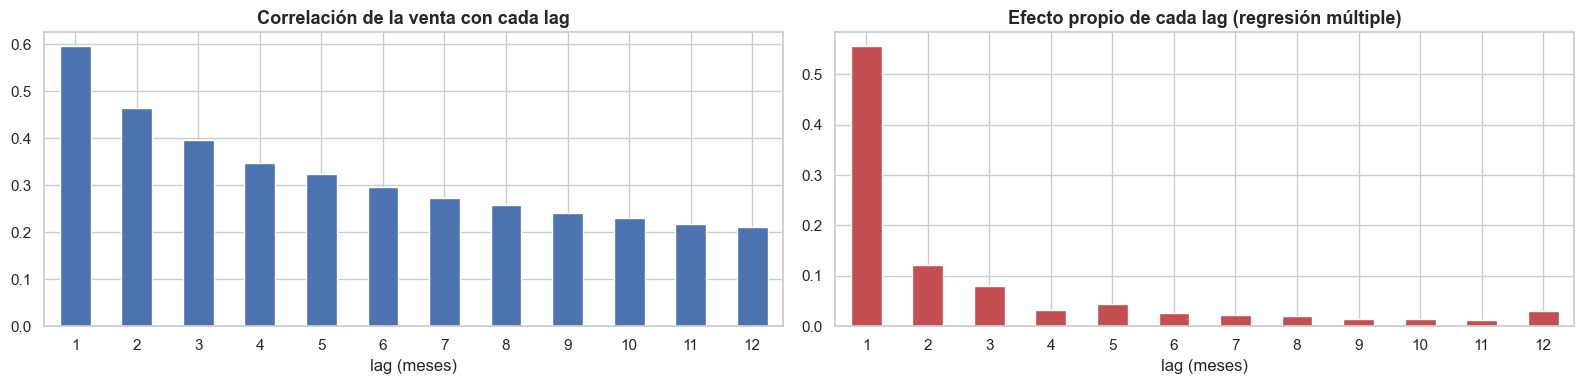

In [3]:
MES_INI_TRAIN, MES_FIN_TRAIN = 12, 26
CANDIDATOS = list(range(1, 13))

constructor = ConstructorRezagos(historia, items_cat, tiendas_cat, rezagos_par=CANDIDATOS, rezagos_item=(), rezagos_tienda=(), rezagos_categoria=(), mapa_tiendas=MAPA_TIENDAS)
train = grid[grid["date_block_num"].between(MES_INI_TRAIN, MES_FIN_TRAIN)]
muestra = train.sample(min(1_000_000, len(train)), random_state=42)
lags = constructor.fit(muestra[COLS_ID]).transform(muestra[COLS_ID])
cols_lag = [f"venta_par_lag_{k}" for k in CANDIDATOS]
y = muestra["item_cnt_month"].to_numpy()

corr = pd.Series([np.corrcoef(lags[c], y)[0, 1] for c in cols_lag], index=CANDIDATOS)
Z = (lags[cols_lag] - lags[cols_lag].mean()) / lags[cols_lag].std()
coef = pd.Series(LinearRegression().fit(Z, y).coef_, index=CANDIDATOS)

tabla_lags = pd.DataFrame({"correlación": corr, "coef_parcial": coef})
display(tabla_lags.round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
corr.plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_title("Correlación de la venta con cada lag")
coef.plot.bar(ax=axes[1], color=["#C44E52" if c > 0 else "#8C8C8C" for c in coef])
axes[1].set_title("Efecto propio de cada lag (regresión múltiple)")
for ax in axes:
    ax.set_xlabel("lag (meses)")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig(FIGS / "02a_seleccion_lags.png", dpi=120, bbox_inches="tight")
plt.show()

**Interpretación (1b):**
- **Lag 1** domina: correlación **0.596** y efecto propio **0.556**, unas 4.5 veces más que el siguiente. Confirma el EDA, donde la PACF cortaba en el rezago 1: la venta del mes anterior es el mejor predictor.
- **Lags 2 y 3** todavía aportan información propia (**0.121** y **0.079**). Desde el **lag 4** el efecto propio baja a menos de 0.05: la correlación simple sigue alta (0.35 → 0.21) solo porque esos lags repiten información de los primeros.
- La correlación **decae lentamente** (0.60 → 0.21): las ventas de un par son **persistentes** en el tiempo.
- El **lag 12** sube respecto a los lags 9–11 (0.031 frente a 0.012–0.015). Es la huella de la **estacionalidad anual** que se encontró en el EDA (pico de diciembre).
- **Lags seleccionados: 1, 2, 3, 5 y 12.** Se toman los 4 de mayor efecto propio, y se fuerzan el 1 (PACF) y el 12 (estacionalidad). El lag 5 (0.044) y el 4 (0.032) son casi iguales; el criterio se queda con el 5.
- Además se agregan rezagos **agregados**: venta media del **producto** (lags 1, 2 y 3), venta total de la **tienda** (lag 1) y venta media de la **categoría** (lag 1). Sirven para el **40.8 % de pares del test** donde el producto es conocido pero nuevo en esa tienda: el par no tiene historia, pero el producto sí.

In [4]:
# Criterio: los 4 lags con mayor efecto propio positivo,
# y siempre el lag 1 (PACF del EDA) y el lag 12 (estacionalidad anual del EDA).
top = coef[coef > 0].sort_values(ascending=False).index[:4].tolist()
LAGS_PAR = sorted(set(top) | {1, 12})
print("Lags seleccionados para el par tienda-producto:", LAGS_PAR)

Lags seleccionados para el par tienda-producto: [1, 2, 3, 5, 12]


## 2. Procesos de ingeniería de características
Se construyen todas las variables sobre una muestra de 500 mil filas de entrenamiento (meses 12–26) y se analiza cada proceso. Los operadores se programan en el notebook 03; aquí solo se decide **qué hacer, a qué variables y con qué criterio**.

In [5]:
LAGS_ITEM, LAGS_TIENDA, LAGS_CATEGORIA = [1, 2, 3], [1], [1]
constructor = ConstructorRezagos(historia, items_cat, tiendas_cat, rezagos_par=LAGS_PAR, rezagos_item=LAGS_ITEM, rezagos_tienda=LAGS_TIENDA, rezagos_categoria=LAGS_CATEGORIA, mapa_tiendas=MAPA_TIENDAS)
muestra = train.sample(min(500_000, len(train)), random_state=42).reset_index(drop=True)
X = constructor.fit(muestra[COLS_ID]).transform(muestra[COLS_ID])
y = muestra["item_cnt_month"].to_numpy()
print("Dimensión de la muestra con variables:", X.shape)
nulos = X.isna().sum()
display(pd.DataFrame({"nulos": nulos, "% nulos": (nulos / len(X) * 100).round(2)})[nulos > 0])
X.head()

Dimensión de la muestra con variables: (500000, 23)


,nulos,% nulos
precio_ultimo_item,24463,4.89


,shop_id,item_id,date_block_num,item_category_id,categoria_grupo,ciudad,tienda_tipo,mes,venta_par_lag_1,venta_par_lag_2,venta_par_lag_3,venta_par_lag_5,venta_par_lag_12,venta_item_lag_1,venta_item_lag_2,venta_item_lag_3,venta_tienda_lag_1,venta_categoria_lag_1,item_nuevo,par_nuevo,item_meses_desde_primera_venta,par_meses_desde_primera_venta,precio_ultimo_item
0,22,20241,18,40,Cine,Moscú,Física,7,0.0,0.0,0.0,0.0,0.0,0.306122,0.285714,0.367347,1163.0,323.469391,0,0,10.0,9.0,194.733337
1,53,4963,17,19,Juegos consola,Ufá,Física,6,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,1605.0,121.489799,1,1,0.0,0.0,NaN
2,19,11601,17,40,Cine,Kursk,Física,6,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,1773.0,301.326538,0,1,17.0,0.0,198.000000
3,24,15735,12,37,Cine,Moscú,Física,1,0.0,0.0,0.0,0.0,0.0,0.021739,0.022222,0.000000,3436.0,215.347824,0,1,12.0,0.0,179.000000
4,51,17449,19,40,Cine,Tiumén,Física,8,0.0,0.0,0.0,0.0,0.0,0.100000,0.000000,0.000000,1295.0,286.179993,0,0,19.0,13.0,135.199997


**Interpretación:** la muestra tiene **500,000 filas y 23 variables**. La única con faltantes es `precio_ultimo_item` (**24,463 filas, 4.89 %**). Los lags no tienen nulos porque el entrenamiento empieza en el mes 12, así que hasta el lag 12 siempre tiene historia.

### i. Imputación de variables numéricas
`precio_ultimo_item` (último precio del producto en meses anteriores) queda vacío cuando el producto **nunca se había vendido**. Criterio: se imputa con la **mediana del precio de su categoría**, porque el precio cambia mucho entre categorías (una consola no cuesta lo mismo que un DVD). Se usa la mediana y no la media porque el precio es muy asimétrico.
Los lags de venta se imputan con **0** cuando el mes cae antes del inicio de los datos: si no hay registro, no hubo venta.

In [6]:
print(f"% de filas sin precio previo del producto: {X['precio_ultimo_item'].isna().mean() * 100:.2f} %")
print(f"De ellas, % que son productos nuevos:      {X.loc[X['precio_ultimo_item'].isna(), 'item_nuevo'].mean() * 100:.1f} %")
med_grupo = X.groupby("categoria_grupo")["precio_ultimo_item"].median().sort_values()
display(med_grupo.round(0).to_frame("mediana de precio"))
print(f"Mediana global: {X['precio_ultimo_item'].median():,.0f}")
mediana_cat = X.groupby("item_category_id")["precio_ultimo_item"].median()
imputado = X["precio_ultimo_item"].fillna(X["item_category_id"].map(mediana_cat)).fillna(X["precio_ultimo_item"].median())
print(f"Nulos después de imputar: {imputado.isna().sum()}")

% de filas sin precio previo del producto: 4.89 %
De ellas, % que son productos nuevos:      100.0 %


,mediana de precio
categoria_grupo,
Medios vírgenes,41.0
Baterías,103.0
Juegos Android,183.0
Cine,199.0
Juegos PC,299.0
Libros,299.0
Música,299.0
Envíos,616.0
Regalos,724.0


Mediana global: 299
Nulos después de imputar: 0



- El **100 %** de las filas sin precio son **productos nuevos**, que nunca se habían vendido. El faltante es lógico, no un error de captura.
- La mediana del precio cambia muchísimo entre categorías: de **41 rublos** (medios vírgenes) a **10,013** (consolas), unas 244 veces. La mediana global (**299**) subvaloraría mucho una consola nueva. Por eso se imputa con la **mediana de su categoría**.
- *Juegos MAC* sale sin mediana porque ninguno de sus productos tiene precio previo en la muestra. En esos casos el imputador usa la **mediana global** como respaldo.
- Después de imputar quedan **0 nulos**.

### ii. Imputación de variables categóricas
Las variables categóricas (`categoria_grupo`, `ciudad`, `tienda_tipo`) no tienen faltantes, así que se **fuerza** el proceso eliminando al azar el **2 %** de sus valores. Criterio: se imputa con la **moda**, porque son variables nominales con pocos faltantes y la moda no crea categorías artificiales.

In [7]:
rng = np.random.default_rng(42)
X_forzado = X.copy()
CAT_VARS = ["categoria_grupo", "ciudad", "tienda_tipo"]
for v in CAT_VARS:
    idx = rng.choice(len(X_forzado), size=int(0.02 * len(X_forzado)), replace=False)
    X_forzado.loc[idx, v] = np.nan
print("Nulos forzados (2 %):", X_forzado[CAT_VARS].isna().sum().to_dict())
modas = {v: X_forzado[v].mode().iloc[0] for v in CAT_VARS}
print("Moda de cada variable:", modas)
for v in CAT_VARS:
    X_forzado[v] = X_forzado[v].fillna(modas[v])
print("Nulos después de imputar:", X_forzado[CAT_VARS].isna().sum().to_dict())

Nulos forzados (2 %): {'categoria_grupo': 10000, 'ciudad': 10000, 'tienda_tipo': 10000}
Moda de cada variable: {'categoria_grupo': 'Cine', 'ciudad': 'Moscú', 'tienda_tipo': 'Física'}
Nulos después de imputar: {'categoria_grupo': 0, 'ciudad': 0, 'tienda_tipo': 0}


se eliminaron al azar **10,000 valores (2 %)** de cada variable categórica y se imputaron con la moda: **Cine**, **Moscú** y **Física**. Coincide con el EDA: Cine es el grupo con más unidades (25 %), Moscú concentra el 35 % de las ventas y la mayoría de tiendas son físicas. Quedan **0 nulos**. En el pipeline, la moda se aprende con el entrenamiento y se aplica a cualquier faltante futuro.

### iii. Codificación de variables categóricas
Criterio según el **número de niveles**:
- **Pocos niveles** (`categoria_grupo`, `tienda_tipo`) → **one-hot encoding**: una columna 0/1 por nivel.
- **Muchos niveles** (`shop_id`, `item_category_id`, `ciudad`) → **target encoding**: cada nivel se reemplaza por la venta media que tuvo en el entrenamiento, con suavizado para niveles con pocos datos. Con one-hot generarían más de 150 columnas casi vacías.
Así la **tienda** y el **producto** entran al modelo como **variables exógenas**.
`item_id` (más de 21 mil niveles) no se codifica. Su información entra por los rezagos del producto.

,niveles
shop_id,53
item_category_id,75
ciudad,31
categoria_grupo,17
tienda_tipo,4


Venta media por tienda: mín 0.059, máx 1.154


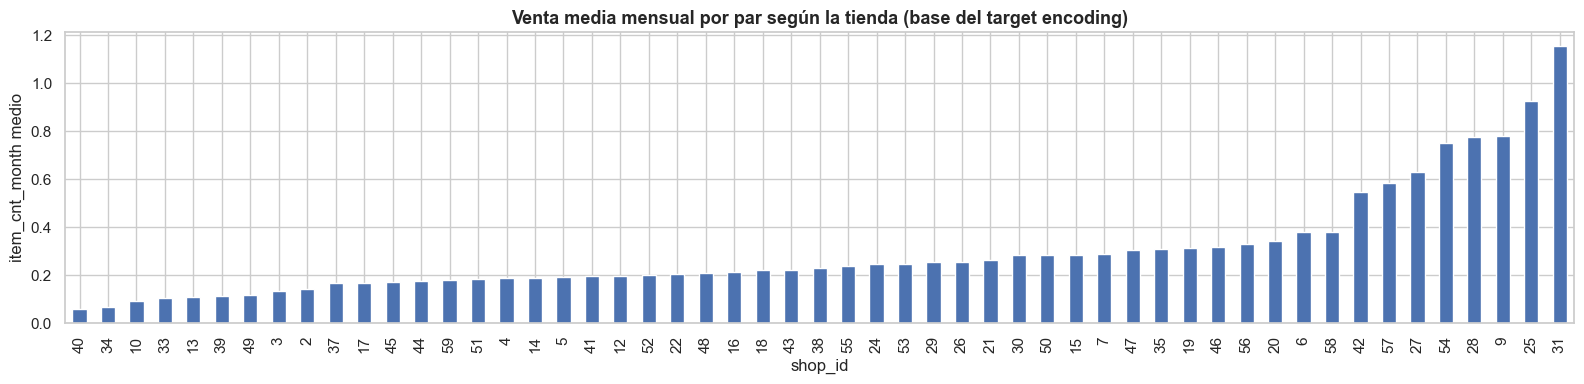

In [8]:
cardinalidad = pd.Series({v: X[v].nunique() for v in ["shop_id", "item_category_id", "ciudad", "categoria_grupo", "tienda_tipo"]})
display(cardinalidad.to_frame("niveles"))
venta_tienda = pd.Series(y).groupby(X["shop_id"]).mean().sort_values()
print(f"Venta media por tienda: mín {venta_tienda.min():.3f}, máx {venta_tienda.max():.3f}")
fig, ax = plt.subplots(figsize=(16, 4))
venta_tienda.plot.bar(ax=ax, color="#4C72B0")
ax.set_title("Venta media mensual por par según la tienda (base del target encoding)")
ax.set_xlabel("shop_id")
ax.set_ylabel("item_cnt_month medio")
plt.tight_layout()
plt.savefig(FIGS / "02b_target_encoding_tienda.png", dpi=120, bbox_inches="tight")
plt.show()


- Niveles: `shop_id` **53**, `item_category_id` **75**, `ciudad` **31**, `categoria_grupo` **17**, `tienda_tipo` **4**.
- Con one-hot, tienda + categoría + ciudad sumarían ~159 columnas casi vacías. Por eso esas tres van con **target encoding**; `categoria_grupo` y `tienda_tipo` (pocos niveles) van con **one-hot**.
- La venta media por par cambia unas **20 veces** entre tiendas: de **0.059** (tienda 40) a **1.154** (tienda 31, Semenovsky, la líder del EDA). La tienda determina el nivel de venta, así que entra al modelo como **variable exógena** con este valor.
- La tienda **9 (itinerante)** aparece entre las más altas porque solo opera en ferias, con pocos productos muy vendidos.

### iv. Tratamiento de outliers
El EDA mostró precios y cantidades extremas reales (consolas, licencias, bolsas de marca). No se eliminan; se **acotan** (winsorización):
- `precio_ultimo_item` → límites **IQR sobre la escala logarítmica**, el mismo criterio del EDA (7c).
- `venta_item_lag_*` (venta media del producto) → límite en el **percentil 99.5**. No se usa IQR porque la mayoría de valores son 0 y el IQR sale 0.
- La venta del par ya está acotada a [0, 20].

Precio: límites IQR (escala log) = [26, 5,141] rublos
Precio: % de filas fuera de los límites = 1.37 %
Venta media del producto (lag 1): percentil 99.5 = 5.86  (máximo = 19.24)


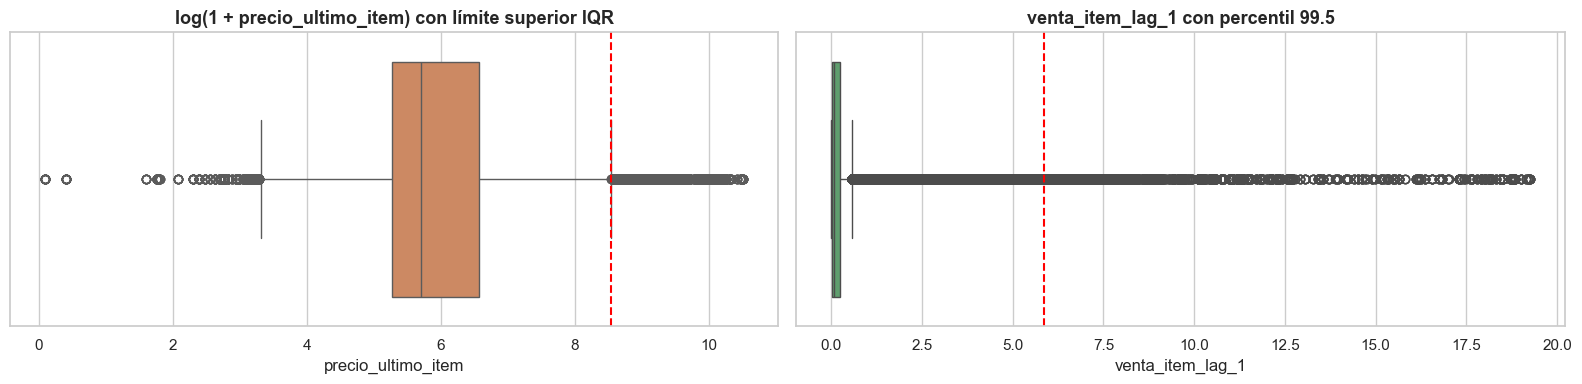

In [9]:
p = X["precio_ultimo_item"].dropna()
lp = np.log1p(p)
q1, q3 = lp.quantile([0.25, 0.75])
iqr = q3 - q1
lim_inf, lim_sup = np.expm1(q1 - 1.5 * iqr), np.expm1(q3 + 1.5 * iqr)
print(f"Precio: límites IQR (escala log) = [{lim_inf:,.0f}, {lim_sup:,.0f}] rublos")
print(f"Precio: % de filas fuera de los límites = {((p < lim_inf) | (p > lim_sup)).mean() * 100:.2f} %")
lim_item = np.percentile(X["venta_item_lag_1"], 99.5)
print(f"Venta media del producto (lag 1): percentil 99.5 = {lim_item:.2f}  (máximo = {X['venta_item_lag_1'].max():.2f})")

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
sns.boxplot(x=lp, ax=axes[0], color="#DD8452")
axes[0].axvline(np.log1p(lim_sup), ls="--", color="red")
axes[0].set_title("log(1 + precio_ultimo_item) con límite superior IQR")
sns.boxplot(x=X["venta_item_lag_1"], ax=axes[1], color="#55A868")
axes[1].axvline(lim_item, ls="--", color="red")
axes[1].set_title("venta_item_lag_1 con percentil 99.5")
plt.tight_layout()
plt.savefig(FIGS / "02b_outliers.png", dpi=120, bbox_inches="tight")
plt.show()


- **Precio:** con IQR en escala log los límites son **[26, 5,141] rublos**. Solo el **1.37 %** de las filas queda fuera; son consolas y productos premium. Se acotan al límite en lugar de eliminarse, porque son ventas reales.
- **Venta media del producto (lag 1):** el percentil 99.5 es **5.86**, pero el máximo llega a **19.24**: unos pocos productos muy vendidos (bolsa de marca, lanzamientos) estiran la escala. Acotarlos evita que dominen el ajuste de los modelos lineales.

### v. Transformación de variables numéricas
Criterio: a las variables **continuas con asimetría alta** (|asimetría| > 1) se les aplica **log(1 + x)**. Comprime los valores grandes y acerca la distribución a una normal, lo que ayuda a los modelos lineales. Se usa log(1 + x) y no log(x) porque hay ceros.

,asimetría original,asimetría log(1+x)
precio_ultimo_item,9.53,0.42
venta_item_lag_1,9.40,3.46
venta_item_lag_2,9.36,3.46
venta_item_lag_3,9.42,3.49
venta_tienda_lag_1,2.45,-4.11
venta_categoria_lag_1,0.98,-0.54


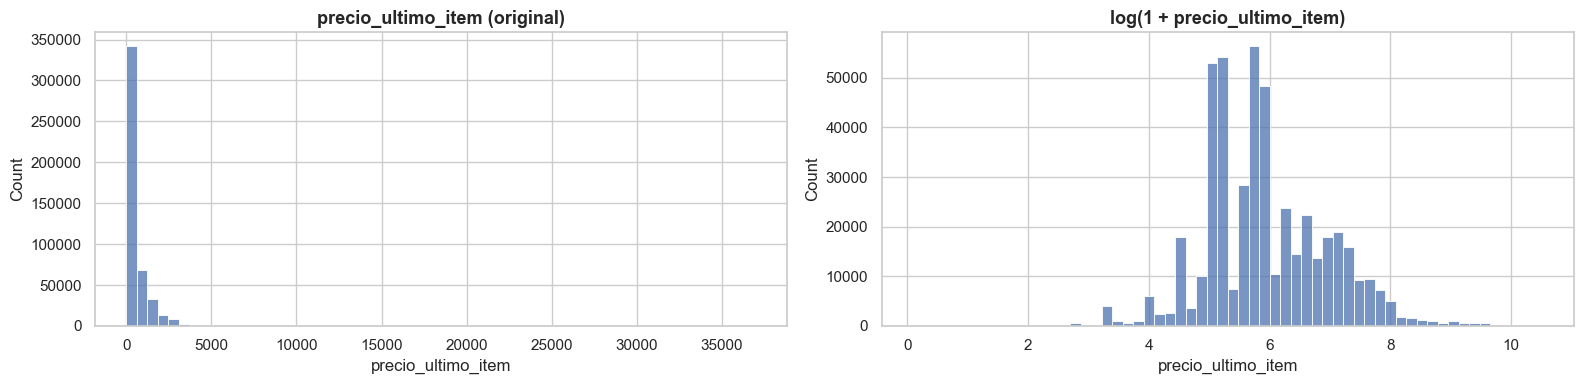

In [10]:
VARS_CONTINUAS = ["precio_ultimo_item"] + [f"venta_item_lag_{k}" for k in LAGS_ITEM] + [f"venta_tienda_lag_{k}" for k in LAGS_TIENDA] + [f"venta_categoria_lag_{k}" for k in LAGS_CATEGORIA]
asimetria = pd.DataFrame({"asimetría original": X[VARS_CONTINUAS].skew(), "asimetría log(1+x)": np.log1p(X[VARS_CONTINUAS].clip(lower=0)).skew()})
display(asimetria.round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 4))
sns.histplot(X["precio_ultimo_item"].dropna(), bins=60, ax=axes[0], color="#4C72B0")
axes[0].set_title("precio_ultimo_item (original)")
sns.histplot(np.log1p(X["precio_ultimo_item"].dropna()), bins=60, ax=axes[1], color="#4C72B0")
axes[1].set_title("log(1 + precio_ultimo_item)")
plt.tight_layout()
plt.savefig(FIGS / "02b_transformacion_log.png", dpi=120, bbox_inches="tight")
plt.show()

### Mapeo (Mapper): mes → índice estacional
El mes del año (1–12) no es una cantidad: diciembre (12) no "vale más" que enero (1). Con un **Mapper** cada mes se reemplaza por su **índice estacional**: cuánto vende ese mes frente al mes promedio del año, como en la sección 6b-ii del EDA. Se calcula **solo con 2013 y 2014** (meses 0–23), para no usar información de la validación.

In [11]:
mensual = df[df["date_block_num"] <= 23].groupby("date_block_num")["item_cnt_day"].sum()
tabla = pd.DataFrame({"año": mensual.index // 12, "mes": mensual.index % 12 + 1, "unidades": mensual.values})
tabla["relativo"] = tabla["unidades"] / tabla.groupby("año")["unidades"].transform("mean")
INDICE_ESTACIONAL = (tabla.groupby("mes")["relativo"].mean() * 100).round(1).to_dict()
print("Índice estacional por mes (100 = mes promedio):", INDICE_ESTACIONAL)

Índice estacional por mes (100 = mes promedio): {1: 103.6, 2: 99.0, 3: 108.9, 4: 85.0, 5: 85.5, 6: 92.4, 7: 86.4, 8: 94.8, 9: 96.3, 10: 97.8, 11: 103.4, 12: 147.0}


### vi. Escalado de características
Las variables quedan en escalas muy distintas (precios en miles de rublos, banderas 0/1, meses de antigüedad). Criterio: **estandarización** (media 0, desviación 1) de todas las variables finales. Es necesaria para los modelos lineales (Ridge), que penalizan los coeficientes por su tamaño. A los árboles no los afecta, así que no les hace daño.

In [12]:
rangos = X.select_dtypes("number").agg(["min", "max", "mean", "std"]).T
display(rangos.round(2).sort_values("std", ascending=False))

,min,max,mean,std
item_id,0.0,22169.00,11296.42,6268.57
venta_tienda_lag_1,0.0,12942.00,2057.88,1633.16
precio_ultimo_item,0.1,36990.00,686.44,1335.62
venta_categoria_lag_1,0.0,586.22,143.92,139.08
shop_id,2.0,59.00,31.85,17.15
item_category_id,2.0,83.00,44.70,15.47
par_meses_desde_primera_venta,0.0,26.00,5.74,7.17
item_meses_desde_primera_venta,0.0,26.00,11.99,7.06
date_block_num,12.0,26.00,18.80,4.29
mes,1.0,12.00,5.63,3.59


In [13]:
VARS_LOG = ["precio_ultimo_item"] + [f"venta_item_lag_{k}" for k in LAGS_ITEM]
config = {
    "mes_ini_train": MES_INI_TRAIN, "mes_fin_train": MES_FIN_TRAIN, "mes_ini_valid": 27, "mes_fin_valid": 33, "mes_test": 34,
    "rezagos_par": LAGS_PAR, "rezagos_item": LAGS_ITEM, "rezagos_tienda": LAGS_TIENDA, "rezagos_categoria": LAGS_CATEGORIA,
    "imputacion_categorica_moda": ["categoria_grupo", "ciudad", "tienda_tipo"],
    "imputacion_numerica_mediana_categoria": ["precio_ultimo_item"],
    "imputacion_numerica_cero": [f"venta_par_lag_{k}" for k in LAGS_PAR] + [f"venta_item_lag_{k}" for k in LAGS_ITEM] + [f"venta_tienda_lag_{k}" for k in LAGS_TIENDA] + [f"venta_categoria_lag_{k}" for k in LAGS_CATEGORIA],
    "outliers_iqr_log": ["precio_ultimo_item"],
    "outliers_percentil_99_5": [f"venta_item_lag_{k}" for k in LAGS_ITEM],
    "transformacion_log": VARS_LOG,
    "mapper_mes_indice_estacional": {int(k): float(v) for k, v in INDICE_ESTACIONAL.items()},
    "target_encoding": ["shop_id", "item_category_id", "ciudad"],
    "one_hot": ["categoria_grupo", "tienda_tipo"],
    "eliminar": ["item_id"],
    "escalado": "StandardScaler (todas las variables finales)",
}
with open(MODELS / "feature_config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)
print("Configuración guardada en", MODELS / "feature_config.json")
print("Variables con log(1+x):", VARS_LOG)

Configuración guardada en c:\Users\icome\Documents\predict-future-sales-eda_parte2\models\feature_config.json
Variables con log(1+x): ['precio_ultimo_item', 'venta_item_lag_1', 'venta_item_lag_2', 'venta_item_lag_3']
